# Train a bilingual prompt-to-scene classifier
Run from the repository’s **ml** folder. Install the packages in requirements.txt first. CPU is sufficient. The synthetic benchmark predicts action, object, and color jointly. It measures generalization to four unseen templates using familiar words and meanings. Two English templates and two Spanish templates are held out.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from train import prepare, fit_numpy, softmax

data, train, test, vocab, meanings, x, y, xt, yt = prepare()
display(data.groupby('language').size(), train.head(), test.head())
print(x.shape, xt.shape)
print('Uniform chance baseline', 1/len(meanings))

(96, 27) (48, 27)
Uniform chance baseline 0.08333333333333333


language
en    72
es    72
dtype: int64

   template language               prompt          meaning
0         0       en    drop the red ball    drop|ball|red
1         0       en   drop the blue ball   drop|ball|blue
2         0       en  drop the green ball  drop|ball|green
3         0       en    drop the red cube    drop|cube|red
4         0       en   drop the blue cube   drop|cube|blue

    template language                         prompt          meaning
48         4       en    could you drop the red ball    drop|ball|red
49         4       en   could you drop the blue ball   drop|ball|blue
50         4       en  could you drop the green ball  drop|ball|green
51         4       en    could you drop the red cube    drop|cube|red
52         4       en   could you drop the blue cube   drop|cube|blue

## NumPy reference model
Inputs are token counts. Train a linear softmax classifier by full-batch gradient descent. Holdout labels enter evaluation only. The web demo uses coefficients exported from this implementation.

In [2]:
w, b, numpy_loss = fit_numpy(x, y, len(meanings))
numpy_pred = softmax(xt @ w + b).argmax(axis=1)

## PyTorch and TensorFlow
Use equivalent zero-initialized linear layers, float32 features, cross-entropy and learning rates. Log every step to compare training curves.

In [3]:
import torch
torch.set_num_threads(1)
layer = torch.nn.Linear(x.shape[1], len(meanings))
torch.nn.init.zeros_(layer.weight)
torch.nn.init.zeros_(layer.bias)
optimizer = torch.optim.SGD(layer.parameters(), lr=0.6)
tx, ty = torch.from_numpy(x), torch.from_numpy(y)
torch_loss = []
for _ in range(650):
    optimizer.zero_grad()
    loss = torch.nn.functional.cross_entropy(layer(tx), ty)
    loss.backward()
    optimizer.step()
    torch_loss.append(loss.item())
with torch.no_grad():
    torch_pred = layer(torch.from_numpy(xt)).argmax(dim=1).numpy()

In [4]:
import tensorflow as tf
with tf.device('/CPU:0'):
    layer_tf = tf.keras.layers.Dense(len(meanings), kernel_initializer='zeros', bias_initializer='zeros')
    tfx = tf.convert_to_tensor(x)
    tfy = tf.convert_to_tensor(y)
    optimizer_tf = tf.keras.optimizers.SGD(learning_rate=0.6)
    tf_loss = []
    for _ in range(650):
        with tf.GradientTape() as tape:
            logits = layer_tf(tfx)
            loss = tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(labels=tfy, logits=logits))
        variables = layer_tf.trainable_variables
        optimizer_tf.apply_gradients(zip(tape.gradient(loss, variables), variables))
        tf_loss.append(float(loss))
    tf_pred = tf.argmax(layer_tf(xt), axis=1).numpy()

NumPy accuracy: 1.0
PyTorch accuracy: 1.0
TensorFlow accuracy: 1.0


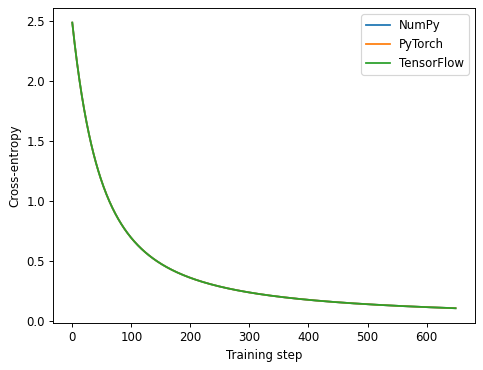

    language  ...        TensorFlow
48        en  ...     drop|ball|red
49        en  ...    drop|ball|blue
50        en  ...   drop|ball|green
51        en  ...     drop|cube|red
52        en  ...    drop|cube|blue
53        en  ...   drop|cube|green
54        en  ...    slide|ball|red
55        en  ...   slide|ball|blue
56        en  ...  slide|ball|green
57        en  ...    slide|cube|red
58        en  ...   slide|cube|blue
59        en  ...  slide|cube|green
60        en  ...     drop|ball|red
61        en  ...    drop|ball|blue
62        en  ...   drop|ball|green
63        en  ...     drop|cube|red
64        en  ...    drop|cube|blue
65        en  ...   drop|cube|green
66        en  ...    slide|ball|red
67        en  ...   slide|ball|blue
68        en  ...  slide|ball|green
69        en  ...    slide|cube|red
70        en  ...   slide|cube|blue
71        en  ...  slide|cube|green
120       es  ...     drop|ball|red
121       es  ...    drop|ball|blue
122       es  ...   drop|bal

          NumPy  PyTorch  TensorFlow
language                            
en          1.0      1.0         1.0
es          1.0      1.0         1.0

In [5]:
test_results = test[['language', 'prompt', 'meaning']].copy()
for name, prediction, history in [('NumPy', numpy_pred, numpy_loss), ('PyTorch', torch_pred, torch_loss), ('TensorFlow', tf_pred, tf_loss)]:
    test_results[name] = np.array(meanings)[prediction]
    print(name, 'accuracy:', (prediction == yt).mean())
    plt.plot(history, label=name)
plt.xlabel('Training step')
plt.ylabel('Cross-entropy')
plt.legend()
plt.show()
display(test_results)
correct = test_results[['NumPy', 'PyTorch', 'TensorFlow']].eq(test_results['meaning'], axis=0)
display(correct.groupby(test_results['language']).mean())

## Challenge the model
Change an object to a word absent from the vocabulary. The classifier will still distribute probability across known meanings. The web demo’s schema check provides a separate abstention rule. Entropy measures dispersion over familiar meanings and needs calibration and out-of-domain tests before it can support a risk threshold.